# Capstone I: Mutual Fund Analytics
## Notebook: Fund Performance Analytics

**Goal:** rank and compare the 40 schemes, find what drives performance, and build a transparent fund scorecard that feeds the dashboard.

**Sections**
1. Setup and data
2. Leaderboards (1, 3 and 5 year returns)
3. Performance against the benchmark
4. Risk-adjusted performance
5. Peer comparison by sub-category
6. Does cost matter? (expense ratio, Direct vs Regular)
7. Does size matter? (AUM)
8. Do Morningstar ratings mean anything?
9. Drawdown and downside risk
10. Fund scorecard
11. Do investors follow performance?
12. Exports for the dashboard
13. Key findings

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)


def find_processed():
    """Works from notebooks/ (data in ../data/processed), from the project root, or next to the CSVs."""
    for cand in (Path("../data/processed"), Path("data/processed"), Path(".")):
        if cand.exists() and list(cand.glob("*fund_master_clean.csv")):
            return cand
    raise FileNotFoundError(
        "Cleaned CSVs not found. Keep this notebook in notebooks/ (CSVs in ../data/processed) "
        "or put it in the same folder as the *_clean.csv files."
    )


PROC = Path.home() /"processed"
FIG = Path.home() /"reports" / "figures"
print("Reading from:", PROC)
print("Figures to  :", FIG)


def load(name, dates=()):
    df = pd.read_csv(PROC / f"{name}_clean.csv")
    for c in dates:
        df[c] = pd.to_datetime(df[c])
    return df


def save_fig(name):
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

Reading from: C:\Users\Sakshi Mane\processed
Figures to  : C:\Users\Sakshi Mane\reports\figures


In [2]:
USE_NAV_RISK = False   # True = replace reported Sharpe / max drawdown with values calculated from NAV (needs risk_metrics.csv from Notebook 3)

fm = load("fund_master", ["launch_date"])
perf = load("scheme_performance")
tx = load("investor_transactions", ["transaction_date"])

# Descriptive columns come from fund_master so every scheme has the same labels
p = perf.drop(columns=["scheme_name", "fund_house", "category", "plan", "expense_ratio_pct", "expense_ratio_valid"], errors="ignore").merge(
    fm[["amfi_code", "scheme_name", "fund_house", "category", "sub_category", "plan", "benchmark", "risk_category", "expense_ratio_pct"]],
    on="amfi_code", how="left")

if USE_NAV_RISK and (PROC / "risk_metrics.csv").exists():
    rm = pd.read_csv(PROC / "risk_metrics.csv")[["amfi_code", "sharpe", "max_drawdown"]]
    p = p.merge(rm, on="amfi_code")
    p["sharpe_ratio"], p["max_drawdown_pct"] = p["sharpe"], p["max_drawdown"] * 100
    print("Using Sharpe and drawdown calculated from NAV (Notebook 3).")
else:
    print("Using Sharpe and drawdown as reported in scheme_performance.")

p["excess_3yr_pct"] = p["return_3yr_pct"] - p["benchmark_3yr_pct"]
p["short_name"] = p["scheme_name"].str.replace(" - Growth", "", regex=False).str.replace(" Plan", "", regex=False).str[:40]
CR = 1e7
print(len(p), "schemes |", p["fund_house"].nunique(), "fund houses |", p["sub_category"].nunique(), "sub-categories")
p[["short_name", "sub_category", "plan", "return_1yr_pct", "return_3yr_pct", "return_5yr_pct", "sharpe_ratio", "aum_crore"]].head()

Using Sharpe and drawdown as reported in scheme_performance.
40 schemes | 10 fund houses | 12 sub-categories


,short_name,sub_category,plan,return_1yr_pct,return_3yr_pct,return_5yr_pct,sharpe_ratio,aum_crore
0,SBI Bluechip Fund - Regular,Large Cap,Regular,12.42,12.36,14.45,0.88,14288
1,SBI Bluechip Fund - Direct,Large Cap,Direct,15.25,11.30,14.23,0.81,1231
2,SBI Small Cap Fund - Regular,Small Cap,Regular,24.56,23.39,20.67,0.94,19259
3,SBI Small Cap Fund - Direct,Small Cap,Direct,20.59,23.14,21.82,0.93,36061
4,SBI Magnum Gilt Fund - Regular,Gilt,Regular,5.34,6.07,5.43,1.52,24101


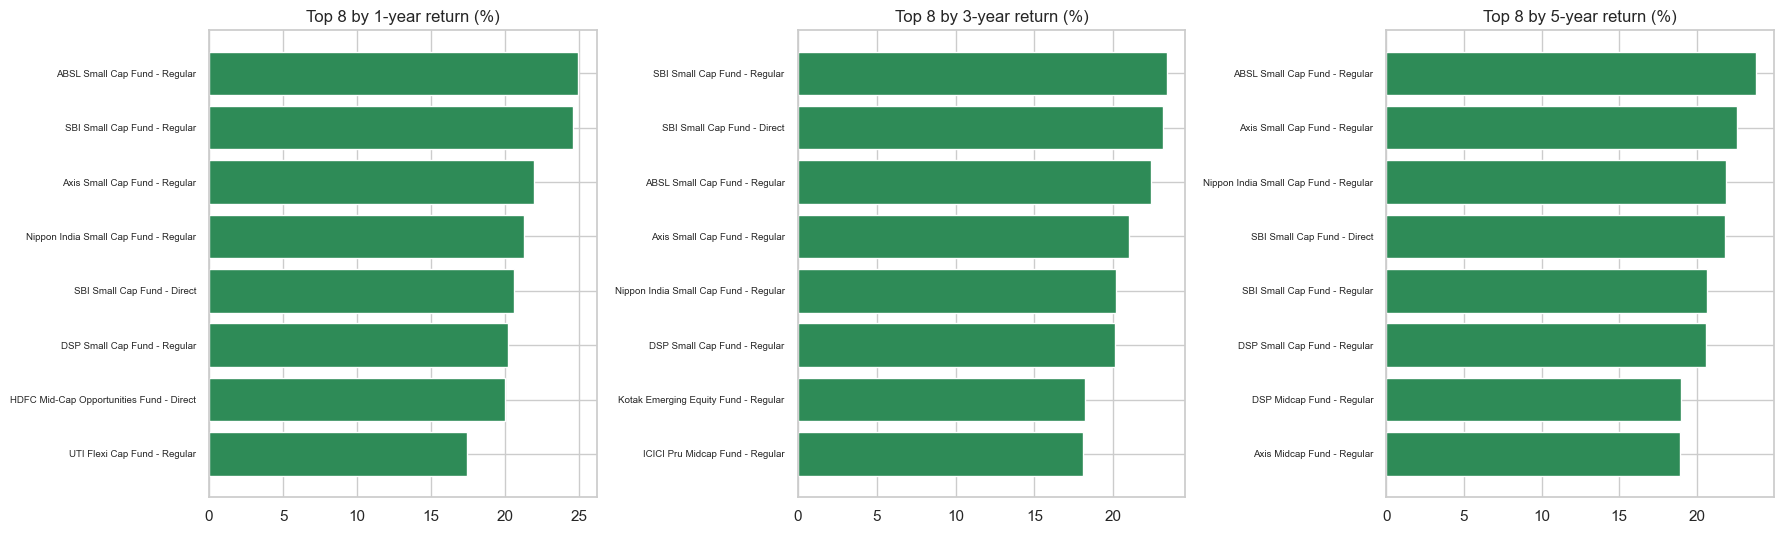

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, col, lab in zip(axes, ["return_1yr_pct", "return_3yr_pct", "return_5yr_pct"], ["1-year", "3-year", "5-year"]):
    top = p.nlargest(8, col).sort_values(col)
    ax.barh(top["short_name"], top[col], color="#2E8B57"); ax.set_title(f"Top 8 by {lab} return (%)"); ax.tick_params(axis="y", labelsize=7)
plt.tight_layout(); save_fig("perf_top_returns"); plt.show()

In [4]:
board = pd.DataFrame({
    "1yr best": p.nlargest(5, "return_1yr_pct")["short_name"].values,
    "3yr best": p.nlargest(5, "return_3yr_pct")["short_name"].values,
    "5yr best": p.nlargest(5, "return_5yr_pct")["short_name"].values,
    "3yr worst": p.nsmallest(5, "return_3yr_pct")["short_name"].values,
}, index=range(1, 6))
board

,1yr best,3yr best,5yr best,3yr worst
1,ABSL Small Cap Fund - Regular,SBI Small Cap Fund - Regular,ABSL Small Cap Fund - Regular,ABSL Liquid Fund - Regular
2,SBI Small Cap Fund - Regular,SBI Small Cap Fund - Direct,Axis Small Cap Fund - Regular,Nippon India Gilt Securities Fund - Regu
3,Axis Small Cap Fund - Regular,ABSL Small Cap Fund - Regular,Nippon India Small Cap Fund - Regular,SBI Magnum Gilt Fund - Regular
4,Nippon India Small Cap Fund - Regular,Axis Small Cap Fund - Regular,SBI Small Cap Fund - Direct,Kotak Liquid Fund - Regular
5,SBI Small Cap Fund - Direct,Nippon India Small Cap Fund - Regular,SBI Small Cap Fund - Regular,HDFC Short Term Debt Fund - Regular


In [5]:
always_top = set(p.nlargest(10, "return_1yr_pct")["amfi_code"]) & set(p.nlargest(10, "return_3yr_pct")["amfi_code"]) & set(p.nlargest(10, "return_5yr_pct")["amfi_code"])
print("Schemes in the top 10 for ALL three horizons:", len(always_top))
print(p[p["amfi_code"].isin(always_top)]["short_name"].tolist())
print("Rank correlation 1yr vs 3yr:", round(p[["return_1yr_pct", "return_3yr_pct"]].corr("spearman").iloc[0, 1], 2),
      "| 3yr vs 5yr:", round(p[["return_3yr_pct", "return_5yr_pct"]].corr("spearman").iloc[0, 1], 2))

Schemes in the top 10 for ALL three horizons: 7
['SBI Small Cap Fund - Regular', 'SBI Small Cap Fund - Direct', 'Nippon India Small Cap Fund - Regular', 'Kotak Emerging Equity Fund - Regular', 'Axis Small Cap Fund - Regular', 'ABSL Small Cap Fund - Regular', 'DSP Small Cap Fund - Regular']
Rank correlation 1yr vs 3yr: 0.81 | 3yr vs 5yr: 0.86


40 of 40 schemes (100%) beat their benchmark over 3 years. Median excess return: 1.21 pp


,schemes,beat_benchmark,median_excess
sub_category,,,
Short Duration,1,100.00,2.00
Flexi Cap,2,100.00,1.80
Index/ETF,1,100.00,1.80
Large & Mid Cap,1,100.00,1.70
Liquid,3,100.00,1.50
Large Cap,14,100.00,1.30
Gilt,2,100.00,1.20
Mid Cap,7,100.00,1.00
Small Cap,6,100.00,1.00


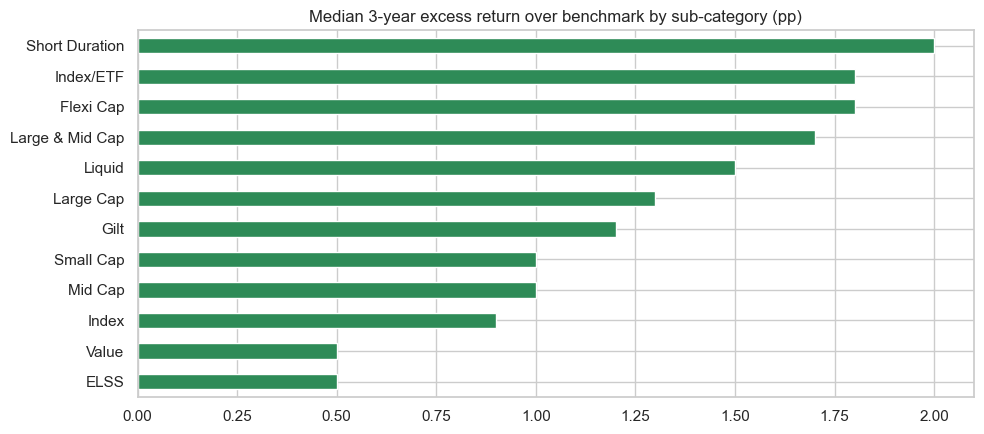

In [6]:
beat = (p["excess_3yr_pct"] > 0)
print(f"{beat.sum()} of {len(p)} schemes ({beat.mean():.0%}) beat their benchmark over 3 years. Median excess return: {p['excess_3yr_pct'].median():.2f} pp")
by_sub = p.groupby("sub_category").agg(schemes=("amfi_code", "count"), beat_benchmark=("excess_3yr_pct", lambda s: (s > 0).mean() * 100), median_excess=("excess_3yr_pct", "median")).round(1)
display(by_sub.sort_values("median_excess", ascending=False))
fig, ax = plt.subplots(figsize=(10, 4.5))
by_sub["median_excess"].sort_values().plot.barh(ax=ax, color=np.where(by_sub["median_excess"].sort_values() >= 0, "#2E8B57", "#C0392B"))
ax.set_title("Median 3-year excess return over benchmark by sub-category (pp)"); ax.set_ylabel("")
plt.tight_layout(); save_fig("perf_excess_by_subcategory"); plt.show()

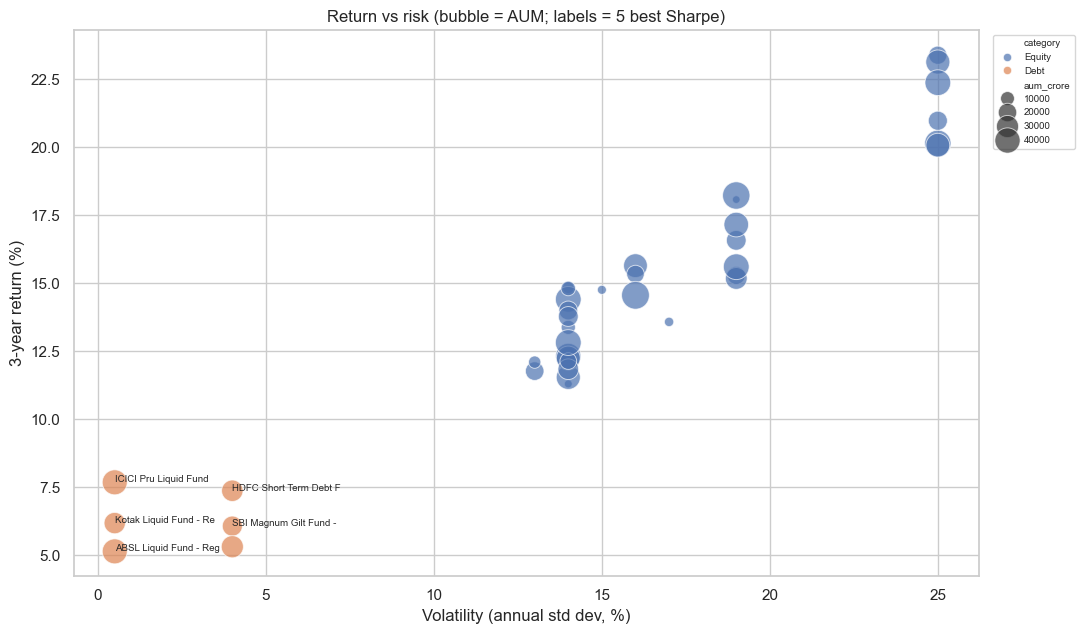

In [7]:
fig, ax = plt.subplots(figsize=(11, 6.5))
sns.scatterplot(data=p, x="std_dev_ann_pct", y="return_3yr_pct", size="aum_crore", sizes=(30, 400), hue="category", alpha=0.7, ax=ax)
for _, r in p.nlargest(5, "sharpe_ratio").iterrows():
    ax.annotate(r["short_name"][:22], (r["std_dev_ann_pct"], r["return_3yr_pct"]), fontsize=7)
ax.set_xlabel("Volatility (annual std dev, %)"); ax.set_ylabel("3-year return (%)"); ax.set_title("Return vs risk (bubble = AUM; labels = 5 best Sharpe)")
ax.legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); save_fig("perf_return_vs_risk"); plt.show()

In [8]:
display(p.nlargest(8, "sharpe_ratio")[["short_name", "sub_category", "sharpe_ratio", "sortino_ratio", "return_3yr_pct", "std_dev_ann_pct"]].reset_index(drop=True))

,short_name,sub_category,sharpe_ratio,sortino_ratio,return_3yr_pct,std_dev_ann_pct
0,ICICI Pru Liquid Fund - Regular,Liquid,7.68,10.37,7.68,0.50
1,Kotak Liquid Fund - Regular,Liquid,6.18,9.70,6.18,0.50
2,ABSL Liquid Fund - Regular,Liquid,5.14,8.76,5.14,0.50
3,HDFC Short Term Debt Fund - Regular,Short Duration,1.84,2.79,7.37,4.00
4,SBI Magnum Gilt Fund - Regular,Gilt,1.52,2.11,6.07,4.00
5,Nippon India Gilt Securities Fund - Regu,Gilt,1.33,2.38,5.31,4.00
6,HDFC Top 100 Fund - Regular,Large Cap,1.06,1.70,14.84,14.00
7,Mirae Asset Large Cap Fund - Regular,Large Cap,1.06,1.66,14.81,14.00


In [9]:
peer = p.groupby("sub_category").agg(
    schemes=("amfi_code", "count"), median_1yr=("return_1yr_pct", "median"), median_3yr=("return_3yr_pct", "median"),
    median_5yr=("return_5yr_pct", "median"), median_sharpe=("sharpe_ratio", "median"),
    median_expense=("expense_ratio_pct", "median"), total_aum_crore=("aum_crore", "sum")).round(2).sort_values("median_3yr", ascending=False)
peer

,schemes,median_1yr,median_3yr,median_5yr,median_sharpe,median_expense,total_aum_crore
sub_category,,,,,,,
Small Cap,6,21.64,21.68,21.85,0.87,1.48,197232
Mid Cap,7,15.43,16.58,17.69,0.87,1.38,198984
Flexi Cap,2,16.58,15.50,14.64,0.97,1.54,52924
Value,1,16.67,14.76,12.60,0.98,1.41,2571
Large & Mid Cap,1,14.91,14.56,15.68,0.91,1.52,49046
ELSS,1,11.16,13.58,14.26,0.80,1.60,2989
Large Cap,14,14.24,12.59,13.45,0.90,1.48,324466
Index,1,13.76,12.10,11.31,0.93,1.57,7350
Index/ETF,1,10.14,11.77,12.31,0.91,0.89,20284


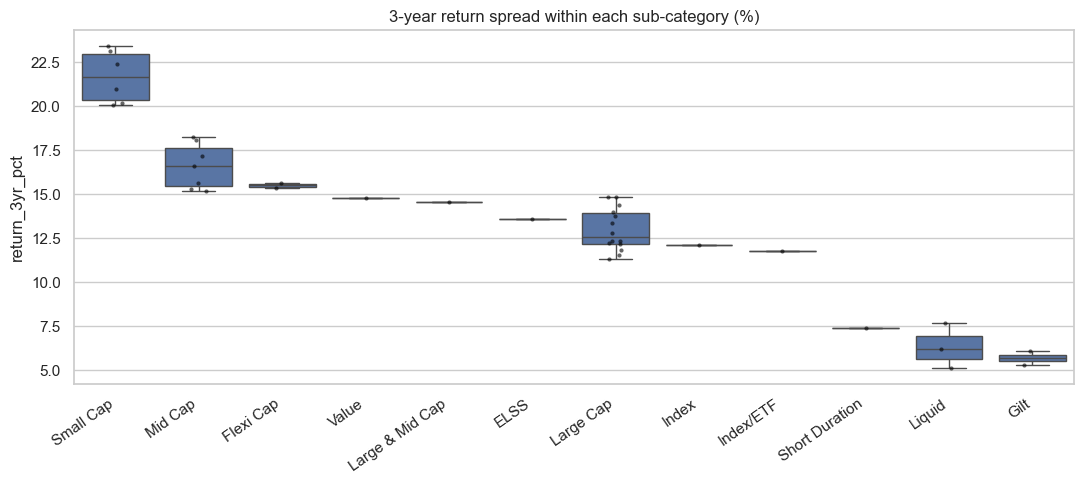

In [10]:
order = p.groupby("sub_category")["return_3yr_pct"].median().sort_values(ascending=False).index
plt.figure(figsize=(11, 5))
sns.boxplot(data=p, x="sub_category", y="return_3yr_pct", order=order)
sns.stripplot(data=p, x="sub_category", y="return_3yr_pct", order=order, color="black", size=3, alpha=0.6)
plt.xticks(rotation=35, ha="right"); plt.xlabel(""); plt.title("3-year return spread within each sub-category (%)")
plt.tight_layout(); save_fig("perf_peer_boxplot"); plt.show()

Equity: 3-year return vs expense ratio -> correlation r = 0.12, slope = 1.32 pp of return per +1 pp expense, p = 0.487


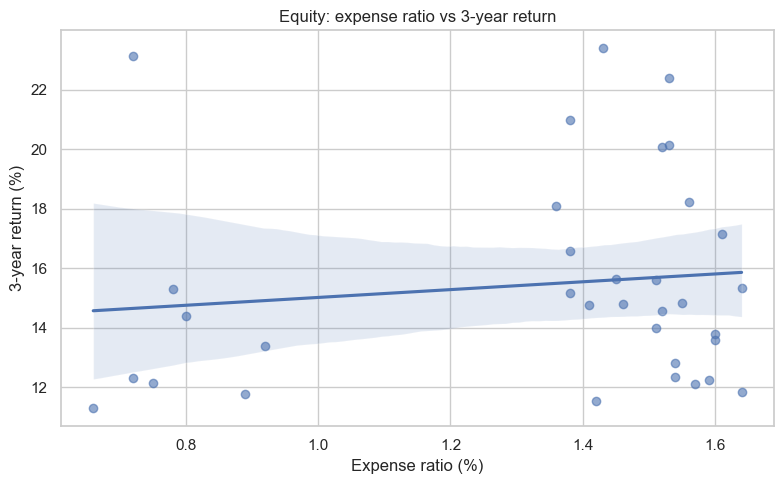

In [11]:
eq = p[p["category"] == "Equity"].copy()
res = stats.linregress(eq["expense_ratio_pct"], eq["return_3yr_pct"])
print(f"Equity: 3-year return vs expense ratio -> correlation r = {res.rvalue:.2f}, slope = {res.slope:.2f} pp of return per +1 pp expense, p = {res.pvalue:.3f}")
plt.figure(figsize=(8, 5))
sns.regplot(data=eq, x="expense_ratio_pct", y="return_3yr_pct", scatter_kws={"alpha": 0.6})
plt.title("Equity: expense ratio vs 3-year return"); plt.xlabel("Expense ratio (%)"); plt.ylabel("3-year return (%)")
plt.tight_layout(); save_fig("perf_expense_vs_return"); plt.show()

In [12]:
plan = p.groupby("plan")[["expense_ratio_pct", "return_1yr_pct", "return_3yr_pct", "return_5yr_pct", "sharpe_ratio"]].mean().round(2)
display(plan)
d, r = p[p["plan"] == "Direct"]["return_3yr_pct"], p[p["plan"] == "Regular"]["return_3yr_pct"]
t = stats.ttest_ind(d, r, equal_var=False)
print(f"Direct minus Regular 3-year return: {d.mean() - r.mean():+.2f} pp (Welch t-test p = {t.pvalue:.3f})")
print("Cost gap (Regular minus Direct expense ratio):", round(p[p['plan'] == 'Regular']['expense_ratio_pct'].mean() - p[p['plan'] == 'Direct']['expense_ratio_pct'].mean(), 2), "pp a year")

,expense_ratio_pct,return_1yr_pct,return_3yr_pct,return_5yr_pct,sharpe_ratio
plan,,,,,
Direct,0.78,14.99,14.22,14.89,0.90
Regular,1.35,14.22,14.06,14.42,1.48


Direct minus Regular 3-year return: +0.16 pp (Welch t-test p = 0.920)
Cost gap (Regular minus Direct expense ratio): 0.57 pp a year


AUM vs return_3yr_pct    : Spearman rho = +0.10 (p = 0.537)
AUM vs sharpe_ratio      : Spearman rho = -0.01 (p = 0.963)
AUM vs expense_ratio_pct : Spearman rho = +0.02 (p = 0.881)


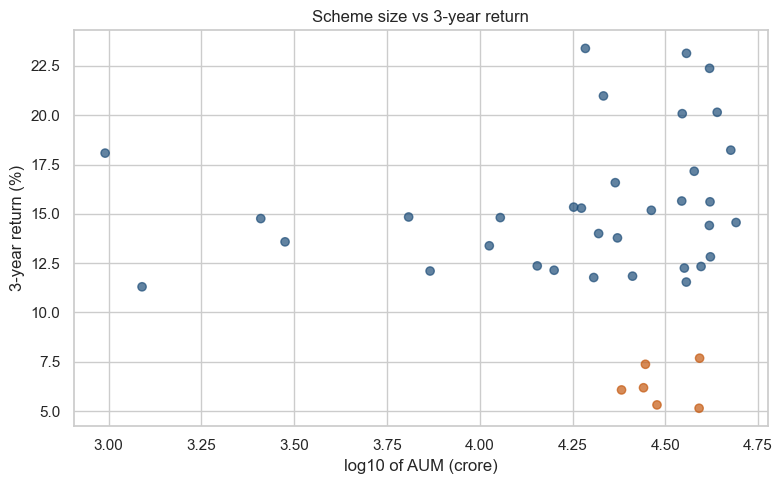

In [13]:
for col in ["return_3yr_pct", "sharpe_ratio", "expense_ratio_pct"]:
    rho, pv = stats.spearmanr(p["aum_crore"], p[col])
    print(f"AUM vs {col:<18}: Spearman rho = {rho:+.2f} (p = {pv:.3f})")
plt.figure(figsize=(8, 5))
plt.scatter(np.log10(p["aum_crore"]), p["return_3yr_pct"], c=np.where(p["category"] == "Equity", "#1F4E79", "#C55A11"), alpha=0.7)
plt.xlabel("log10 of AUM (crore)"); plt.ylabel("3-year return (%)"); plt.title("Scheme size vs 3-year return")
plt.tight_layout(); save_fig("perf_aum_vs_return"); plt.show()

,schemes,avg_3yr,avg_sharpe,avg_expense
morningstar_rating,,,,
3,7,11.70,1.79,0.90
4,16,15.15,0.92,1.28
5,17,14.07,1.60,1.34


Rating vs Sharpe: rho = +0.08 (p = 0.633) | Rating vs 3yr return: rho = +0.16 (p = 0.313)


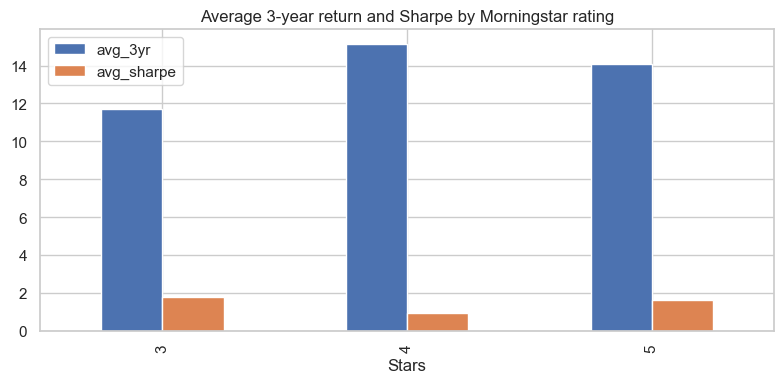

In [14]:
rate = p.groupby("morningstar_rating").agg(schemes=("amfi_code", "count"), avg_3yr=("return_3yr_pct", "mean"), avg_sharpe=("sharpe_ratio", "mean"), avg_expense=("expense_ratio_pct", "mean")).round(2)
display(rate)
rho, pv = stats.spearmanr(p["morningstar_rating"], p["sharpe_ratio"])
rho2, pv2 = stats.spearmanr(p["morningstar_rating"], p["return_3yr_pct"])
print(f"Rating vs Sharpe: rho = {rho:+.2f} (p = {pv:.3f}) | Rating vs 3yr return: rho = {rho2:+.2f} (p = {pv2:.3f})")
rate[["avg_3yr", "avg_sharpe"]].plot.bar(figsize=(8, 4), title="Average 3-year return and Sharpe by Morningstar rating"); plt.xlabel("Stars")
plt.tight_layout(); save_fig("perf_morningstar"); plt.show()

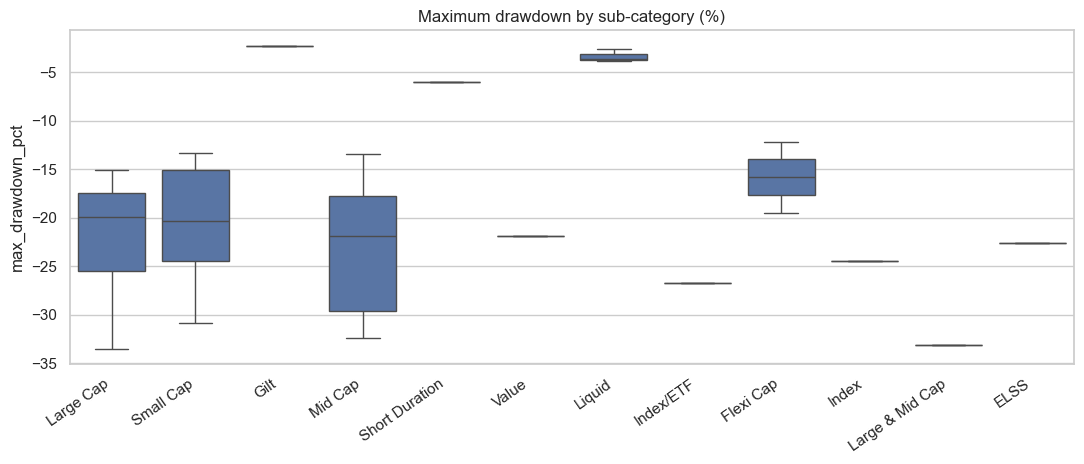

,short_name,sub_category,max_drawdown_pct,std_dev_ann_pct,return_3yr_pct
0,HDFC Top 100 Fund - Direct,Large Cap,-33.50,14.00,13.38
1,Mirae Asset Emerging Bluechip Fund - Reg,Large & Mid Cap,-33.15,16.00,14.56
2,Axis Midcap Fund - Regular,Mid Cap,-32.38,19.00,15.18
3,HDFC Mid-Cap Opportunities Fund - Direct,Mid Cap,-32.22,19.00,15.29
4,Nippon India Small Cap Fund - Regular,Small Cap,-30.87,25.00,20.15


In [15]:
plt.figure(figsize=(11, 4.8))
sns.boxplot(data=p, x="sub_category", y="max_drawdown_pct"); plt.xticks(rotation=35, ha="right"); plt.xlabel("")
plt.title("Maximum drawdown by sub-category (%)")
plt.tight_layout(); save_fig("perf_drawdown_by_subcategory"); plt.show()
display(p.nsmallest(5, "max_drawdown_pct")[["short_name", "sub_category", "max_drawdown_pct", "std_dev_ann_pct", "return_3yr_pct"]].reset_index(drop=True))

In [16]:
WEIGHTS = {"return_3yr_pct": 0.25, "sharpe_ratio": 0.25, "alpha": 0.20, "max_drawdown_pct": 0.15, "expense_ratio_pct": 0.15}
LOWER_IS_BETTER = {"expense_ratio_pct"}


def score(df, weights):
    total = pd.Series(0.0, index=df.index)
    for col, w in weights.items():
        vals = -df[col] if col in LOWER_IS_BETTER else df[col]
        total += w * vals.groupby(df["category"]).rank(pct=True)
    return total / sum(weights.values()) * 100


p["score"] = score(p, WEIGHTS).round(1)
p["rank_in_category"] = p.groupby("category")["score"].rank(ascending=False, method="min").astype(int)
p["tier"] = pd.qcut(p["score"], 4, labels=["Bottom quartile", "Below average", "Above average", "Top quartile"])

cols = ["rank_in_category", "short_name", "category", "sub_category", "plan", "score", "return_3yr_pct", "sharpe_ratio", "alpha", "max_drawdown_pct", "expense_ratio_pct", "tier"]
scorecard = p.sort_values(["category", "rank_in_category"])[cols]
print("Top 10 EQUITY schemes:")
display(scorecard[scorecard["category"] == "Equity"].head(10))
print("Bottom 5 EQUITY schemes:")
display(scorecard[scorecard["category"] == "Equity"].tail(5))
print("All DEBT schemes (ranked among debt funds only):")
display(scorecard[scorecard["category"] == "Debt"])

Top 10 EQUITY schemes:


,rank_in_category,short_name,category,sub_category,plan,score,return_3yr_pct,sharpe_ratio,alpha,max_drawdown_pct,expense_ratio_pct,tier
2,1,SBI Small Cap Fund - Regular,Equity,Small Cap,Regular,76.50,23.39,0.94,1.23,-13.35,1.43,Top quartile
22,2,Kotak Flexicap Fund - Regular,Equity,Flexi Cap,Regular,76.00,15.65,0.98,1.85,-19.50,1.45,Top quartile
34,3,Mirae Asset Large Cap Fund - Regular,Equity,Large Cap,Regular,72.00,14.81,1.06,1.62,-17.07,1.46,Top quartile
21,4,Kotak Emerging Equity Fund - Regular,Equity,Mid Cap,Regular,70.30,18.23,0.96,1.91,-21.92,1.56,Top quartile
3,5,SBI Small Cap Fund - Direct,Equity,Small Cap,Direct,69.60,23.14,0.93,1.13,-24.78,0.72,Top quartile
33,6,UTI Flexi Cap Fund - Regular,Equity,Flexi Cap,Regular,68.00,15.34,0.96,1.79,-12.14,1.64,Top quartile
29,7,ABSL Small Cap Fund - Regular,Equity,Small Cap,Regular,66.20,22.38,0.90,1.84,-23.61,1.53,Top quartile
12,8,ICICI Pru Midcap Fund - Regular,Equity,Mid Cap,Regular,63.40,18.08,0.95,0.89,-21.84,1.36,Top quartile
7,9,HDFC Mid-Cap Opportunities Fund - Regula,Equity,Mid Cap,Regular,59.70,16.58,0.87,0.95,-13.67,1.38,Above average
28,10,ABSL Frontline Equity Fund - Regular,Equity,Large Cap,Regular,58.00,13.78,0.98,1.34,-15.07,1.60,Above average


Bottom 5 EQUITY schemes:


,rank_in_category,short_name,category,sub_category,plan,score,return_3yr_pct,sharpe_ratio,alpha,max_drawdown_pct,expense_ratio_pct,tier
31,30,UTI Nifty 50 Index Fund - Regular,Equity,Index,Regular,36.00,12.10,0.93,0.93,-24.42,1.57,Bottom quartile
0,31,SBI Bluechip Fund - Regular,Equity,Large Cap,Regular,35.80,12.36,0.88,0.87,-21.70,1.54,Bottom quartile
24,32,Axis Bluechip Fund - Regular,Equity,Large Cap,Regular,26.50,11.84,0.85,1.41,-27.54,1.64,Bottom quartile
10,33,ICICI Pru Bluechip Fund - Regular,Equity,Large Cap,Regular,23.00,11.54,0.82,0.66,-25.91,1.42,Bottom quartile
36,34,Mirae Asset Tax Saver Fund - Regular,Equity,ELSS,Regular,20.40,13.58,0.80,0.54,-22.62,1.60,Bottom quartile


All DEBT schemes (ranked among debt funds only):


,rank_in_category,short_name,category,sub_category,plan,score,return_3yr_pct,sharpe_ratio,alpha,max_drawdown_pct,expense_ratio_pct,tier
14,1,ICICI Pru Liquid Fund - Regular,Debt,Liquid,Regular,84.20,7.68,7.68,1.85,-2.62,0.74,Top quartile
9,2,HDFC Short Term Debt Fund - Regular,Debt,Short Duration,Regular,68.30,7.37,1.84,1.98,-6.01,0.56,Top quartile
23,3,Kotak Liquid Fund - Regular,Debt,Liquid,Regular,62.50,6.18,6.18,1.52,-3.81,0.60,Above average
4,4,SBI Magnum Gilt Fund - Regular,Debt,Gilt,Regular,51.70,6.07,1.52,1.60,-2.30,0.77,Below average
19,5,Nippon India Gilt Securities Fund - Regu,Debt,Gilt,Regular,45.80,5.31,1.33,0.89,-2.23,0.55,Below average
30,6,ABSL Liquid Fund - Regular,Debt,Liquid,Regular,37.50,5.14,5.14,1.18,-3.66,0.79,Bottom quartile


Rank correlation between my weights and equal weights: 0.98; top-10 overlap: 9 of 10


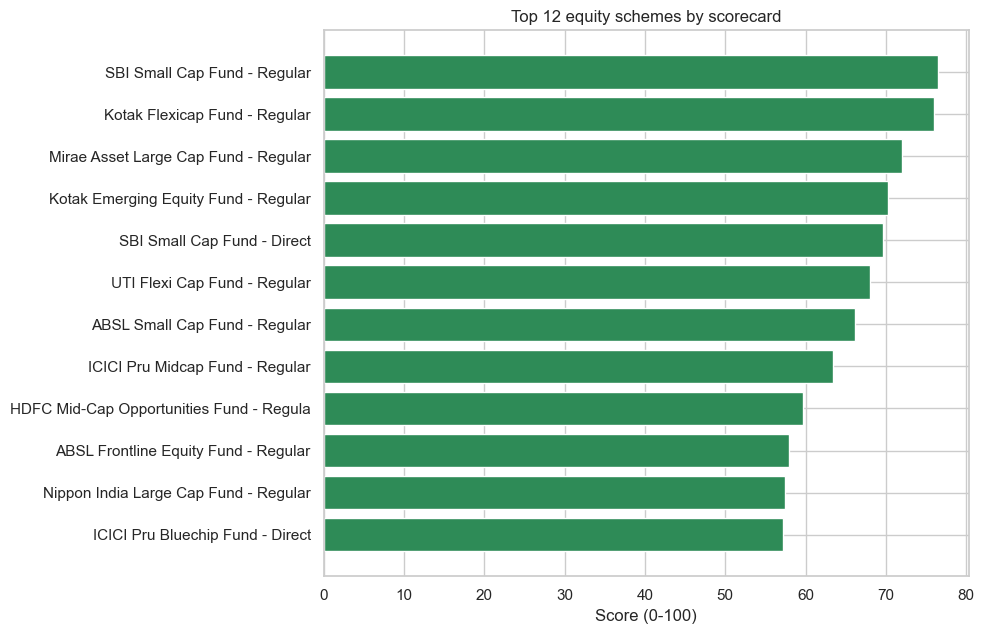

In [17]:
equal = {k: 1 / len(WEIGHTS) for k in WEIGHTS}
alt = score(p, equal)
rho_w = stats.spearmanr(p["score"], alt)[0]
top10_a = set(p.nlargest(10, "score")["amfi_code"]); top10_b = set(p.loc[alt.nlargest(10).index, "amfi_code"])
print(f"Rank correlation between my weights and equal weights: {rho_w:.2f}; top-10 overlap: {len(top10_a & top10_b)} of 10")

plt.figure(figsize=(10, 6.5))
top = scorecard[scorecard["category"] == "Equity"].head(12).iloc[::-1]
plt.barh(top["short_name"], top["score"], color="#2E8B57"); plt.xlabel("Score (0-100)"); plt.title("Top 12 equity schemes by scorecard")
plt.tight_layout(); save_fig("perf_scorecard_top"); plt.show()

Net investor flow vs return_3yr_pct : Spearman rho = -0.07 (p = 0.649)
Net investor flow vs sharpe_ratio   : Spearman rho = -0.01 (p = 0.953)
Net investor flow vs score          : Spearman rho = +0.02 (p = 0.881)


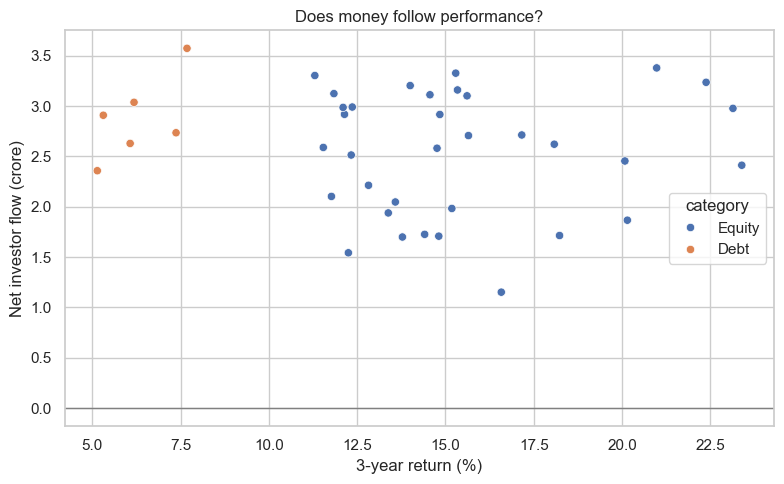

In [18]:
txs = tx[["amfi_code", "transaction_type", "amount_inr"]].copy()
txs["signed"] = np.where(txs["transaction_type"] == "Redemption", -txs["amount_inr"], txs["amount_inr"])
flow = txs.groupby("amfi_code").agg(net_flow_cr=("signed", lambda s: s.sum() / CR), investments=("amount_inr", "count")).reset_index()
pf = p.merge(flow, on="amfi_code", how="left")
for col in ["return_3yr_pct", "sharpe_ratio", "score"]:
    rho, pv = stats.spearmanr(pf[col], pf["net_flow_cr"], nan_policy="omit")
    print(f"Net investor flow vs {col:<15}: Spearman rho = {rho:+.2f} (p = {pv:.3f})")
plt.figure(figsize=(8, 5))
sns.scatterplot(data=pf, x="return_3yr_pct", y="net_flow_cr", hue="category")
plt.axhline(0, color="grey", lw=1); plt.xlabel("3-year return (%)"); plt.ylabel("Net investor flow (crore)")
plt.title("Does money follow performance?")
plt.tight_layout(); save_fig("perf_flow_vs_return"); plt.show()

In [19]:
OUT = PROC.parent / "dashboard_data" if PROC.name == "processed" else Path("dashboard_data")
OUT.mkdir(parents=True, exist_ok=True)

scorecard_full = pf.sort_values(["category", "rank_in_category"])[
    ["rank_in_category", "amfi_code", "scheme_name", "fund_house", "category", "sub_category", "plan", "benchmark",
     "risk_category", "score", "tier", "return_1yr_pct", "return_3yr_pct", "return_5yr_pct", "benchmark_3yr_pct", "excess_3yr_pct",
     "alpha", "beta", "sharpe_ratio", "sortino_ratio", "std_dev_ann_pct", "max_drawdown_pct", "expense_ratio_pct",
     "aum_crore", "morningstar_rating", "net_flow_cr"]]
scorecard_full.to_csv(OUT / "fund_scorecard.csv", index=False)
peer.reset_index().to_csv(OUT / "peer_comparison.csv", index=False)

tx2 = tx.assign(month=tx["transaction_date"].dt.to_period("M").dt.to_timestamp())
tx2.groupby(["month", "transaction_type"])["amount_inr"].sum().div(CR).rename("amount_crore").reset_index().to_csv(OUT / "monthly_flows.csv", index=False)
print("Saved to", OUT)
for f in sorted(OUT.glob("*.csv")):
    print(" ", f.name, f"{f.stat().st_size / 1024:,.0f} KB")

Saved to C:\Users\Sakshi Mane\dashboard_data
  fund_scorecard.csv 10 KB
  monthly_flows.csv 2 KB
  peer_comparison.csv 1 KB


In [20]:
eq_sc, db_sc = scorecard[scorecard["category"] == "Equity"], scorecard[scorecard["category"] == "Debt"]
best, worst, best_debt = eq_sc.iloc[0], eq_sc.iloc[-1], db_sc.iloc[0]
rho_cost = stats.spearmanr(eq["expense_ratio_pct"], eq["return_3yr_pct"])[0]
best_sub = peer.index[0]
findings = [
    f"Top equity scheme on the scorecard: {best['short_name']} (score {best['score']:.0f}); lowest equity: {worst['short_name']} (score {worst['score']:.0f}). Top debt scheme: {best_debt['short_name']} (score {best_debt['score']:.0f}).",
    f"{(p['excess_3yr_pct'] > 0).sum()} of {len(p)} schemes beat their benchmark over 3 years; median excess return {p['excess_3yr_pct'].median():+.2f} pp.",
    f"Best sub-category by median 3-year return: {best_sub} ({peer.iloc[0]['median_3yr']:.1f}%).",
    f"Direct plans average {plan.loc['Direct', 'expense_ratio_pct']:.2f}% expense vs {plan.loc['Regular', 'expense_ratio_pct']:.2f}% for Regular, and {plan.loc['Direct', 'return_3yr_pct']:.1f}% vs {plan.loc['Regular', 'return_3yr_pct']:.1f}% 3-year return.",
    f"Within equity funds, expense ratio and 3-year return have a rank correlation of {rho_cost:+.2f}.",
    f"Scheme size has little link to returns (Spearman {stats.spearmanr(p['aum_crore'], p['return_3yr_pct'])[0]:+.2f}).",
    f"Morningstar stars vs Sharpe ratio: Spearman {stats.spearmanr(p['morningstar_rating'], p['sharpe_ratio'])[0]:+.2f}.",
    f"Net investor flow vs 3-year return: Spearman {stats.spearmanr(pf['return_3yr_pct'], pf['net_flow_cr'], nan_policy='omit')[0]:+.2f}.",
    f"Scorecard ranking is {'stable' if rho_w > 0.8 else 'sensitive'} to weights (rank correlation {rho_w:.2f} against equal weights).",
]
for f in findings:
    print("-", f)

- Top equity scheme on the scorecard: SBI Small Cap Fund - Regular (score 76); lowest equity: Mirae Asset Tax Saver Fund - Regular (score 20). Top debt scheme: ICICI Pru Liquid Fund - Regular (score 84).
- 40 of 40 schemes beat their benchmark over 3 years; median excess return +1.21 pp.
- Best sub-category by median 3-year return: Small Cap (21.7%).
- Direct plans average 0.78% expense vs 1.35% for Regular, and 14.2% vs 14.1% 3-year return.
- Within equity funds, expense ratio and 3-year return have a rank correlation of +0.02.
- Scheme size has little link to returns (Spearman +0.10).
- Morningstar stars vs Sharpe ratio: Spearman +0.08.
- Net investor flow vs 3-year return: Spearman -0.07.
- Scorecard ranking is stable to weights (rank correlation 0.98 against equal weights).
